<a href="https://colab.research.google.com/github/Mahfuj-976/D-PROD/blob/main/Road_accident_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
from collections import Counter
from imblearn.over_sampling import SMOTE
import matplotlib.ticker as ticker
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,MinMaxScaler,LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RepeatedStratifiedKFold,GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier,AdaBoostClassifier,GradientBoostingClassifier
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
from sklearn.model_selection import KFold
import warnings
%matplotlib inline

In [3]:
df = pd.read_csv('/content/RTA Dataset.csv')
df.head()

,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,...,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
0,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,Above 10yr,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury
1,17:02:00,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury
2,17:02:00,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,NaN,...,Going straight,Driver or rider,Male,31-50,3,Driver,NaN,Not a Pedestrian,Changing lane to the left,Serious Injury
3,1:06:00,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,NaN,...,Going straight,Pedestrian,Female,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury
4,1:06:00,Sunday,18-30,Male,Junior high school,Employee,2-5yr,NaN,Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury


In [4]:
df.sample(5)

,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,...,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
6745,22:30:00,Sunday,31-50,Male,Junior high school,Owner,Above 10yr,Automobile,Owner,1-2yr,...,Other,na,na,na,na,Driver,Normal,Not a Pedestrian,Changing lane to the left,Slight Injury
2322,7:55:00,Monday,18-30,Male,High school,Owner,5-10yr,Public (12 seats),Owner,NaN,...,Going straight,Driver or rider,Male,18-30,3,Driver,Normal,Not a Pedestrian,No distancing,Slight Injury
1579,10:27:00,Monday,31-50,Male,Junior high school,Employee,1-2yr,Lorry (11?40Q),Owner,Unknown,...,Going straight,Passenger,Female,31-50,3,Driver,Normal,Not a Pedestrian,Driving carelessly,Slight Injury
6096,17:00:00,Tuesday,Under 18,Male,Junior high school,Employee,Above 10yr,Automobile,Owner,NaN,...,Going straight,na,na,na,na,Driver,Normal,Not a Pedestrian,Driving carelessly,Slight Injury
3139,22:06:00,Thursday,31-50,Male,Junior high school,Employee,5-10yr,Lorry (41?100Q),Owner,2-5yrs,...,Going straight,Driver or rider,Male,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the left,Slight Injury


In [5]:
df.shape

(12316, 32)

In [6]:
df.columns

Index(['Time', 'Day_of_week', 'Age_band_of_driver', 'Sex_of_driver',
       'Educational_level', 'Vehicle_driver_relation', 'Driving_experience',
       'Type_of_vehicle', 'Owner_of_vehicle', 'Service_year_of_vehicle',
       'Defect_of_vehicle', 'Area_accident_occured', 'Lanes_or_Medians',
       'Road_allignment', 'Types_of_Junction', 'Road_surface_type',
       'Road_surface_conditions', 'Light_conditions', 'Weather_conditions',
       'Type_of_collision', 'Number_of_vehicles_involved',
       'Number_of_casualties', 'Vehicle_movement', 'Casualty_class',
       'Sex_of_casualty', 'Age_band_of_casualty', 'Casualty_severity',
       'Work_of_casuality', 'Fitness_of_casuality', 'Pedestrian_movement',
       'Cause_of_accident', 'Accident_severity'],
      dtype='object')

In [7]:
df.describe(include="all")

,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,...,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
count,12316,12316,12316,12316,11575,11737,11487,11366,11834,8388,...,12008,12316,12316,12316,12316,9118,9681,12316,12316,12316
unique,1074,7,5,3,7,4,7,17,4,6,...,13,4,3,6,4,7,5,9,20,3
top,15:30:00,Friday,18-30,Male,Junior high school,Employee,5-10yr,Automobile,Owner,Unknown,...,Going straight,Driver or rider,Male,na,3,Driver,Normal,Not a Pedestrian,No distancing,Slight Injury
freq,120,2041,4271,11437,7619,9627,3363,3205,10459,2883,...,8158,4944,5253,4443,7076,5903,9608,11390,2263,10415
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
df.dtypes

,0
Time,object
Day_of_week,object
Age_band_of_driver,object
Sex_of_driver,object
Educational_level,object
Vehicle_driver_relation,object
Driving_experience,object
Type_of_vehicle,object
Owner_of_vehicle,object
Service_year_of_vehicle,object


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12316 entries, 0 to 12315
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Time                         12316 non-null  object
 1   Day_of_week                  12316 non-null  object
 2   Age_band_of_driver           12316 non-null  object
 3   Sex_of_driver                12316 non-null  object
 4   Educational_level            11575 non-null  object
 5   Vehicle_driver_relation      11737 non-null  object
 6   Driving_experience           11487 non-null  object
 7   Type_of_vehicle              11366 non-null  object
 8   Owner_of_vehicle             11834 non-null  object
 9   Service_year_of_vehicle      8388 non-null   object
 10  Defect_of_vehicle            7889 non-null   object
 11  Area_accident_occured        12077 non-null  object
 12  Lanes_or_Medians             11931 non-null  object
 13  Road_allignment              12

In [10]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
12311,False
12312,False
12313,False
12314,False


In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.groupby('Accident_severity').size()

,0
Accident_severity,
Fatal injury,158
Serious Injury,1743
Slight Injury,10415


In [13]:
df.isnull().sum()

,0
Time,0
Day_of_week,0
Age_band_of_driver,0
Sex_of_driver,0
Educational_level,741
Vehicle_driver_relation,579
Driving_experience,829
Type_of_vehicle,950
Owner_of_vehicle,482
Service_year_of_vehicle,3928


**Numerical data analysis**
---



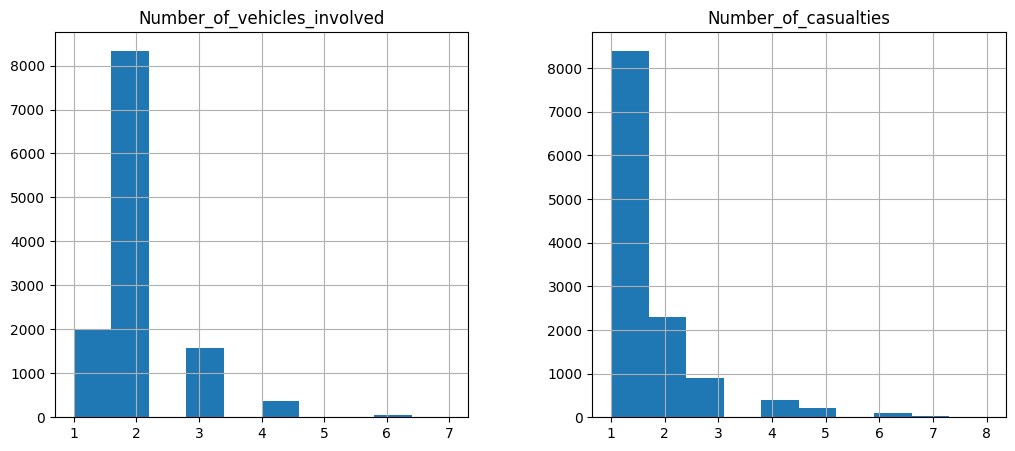

In [14]:
df.hist(layout=(1,6), figsize=(40,5))
plt.show()

In [15]:
df['Number_of_casualties'].value_counts()

,count
Number_of_casualties,
1,8397
2,2290
3,909
4,394
5,207
6,89
7,22
8,8


In [16]:
df['Number_of_vehicles_involved']

,Number_of_vehicles_involved
0,2
1,2
2,2
3,2
4,2
...,...
12311,2
12312,2
12313,1
12314,2


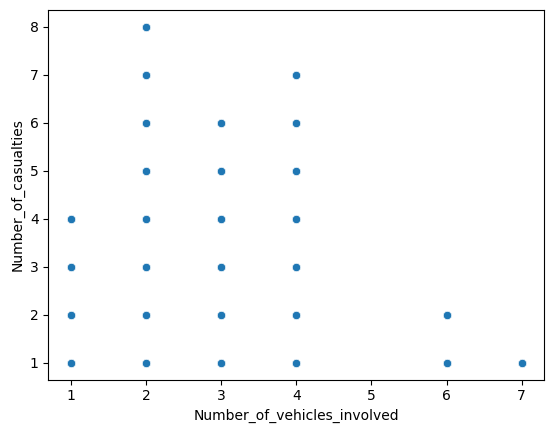

In [17]:
sns.scatterplot(x=df['Number_of_vehicles_involved'], y=df['Number_of_casualties'])
plt.show()

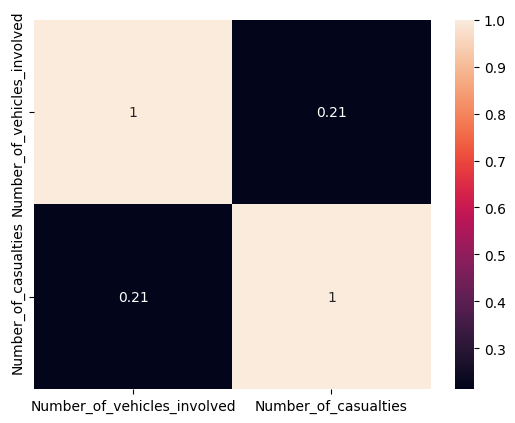

In [18]:
correlation_matrix = df[['Number_of_vehicles_involved','Number_of_casualties']].corr()
sns.heatmap(correlation_matrix, annot=True)
plt.show()

**Categorical data analysis**
---



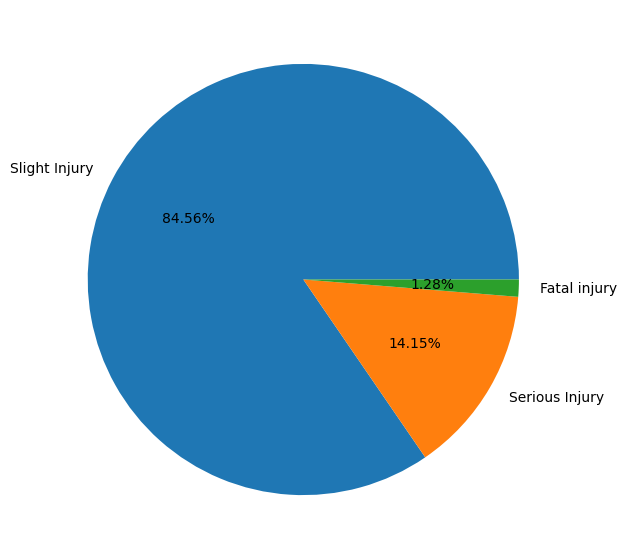

In [19]:
plt.figure(figsize=(10,7))
plt.pie(x=df['Accident_severity'].value_counts().values,
        labels=df['Accident_severity'].value_counts().index,
        autopct='%2.2f%%')
plt.show()

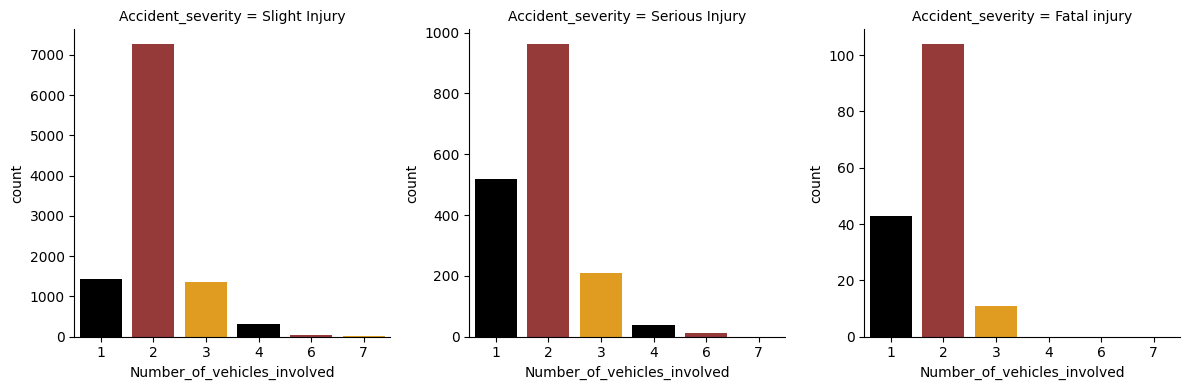

In [20]:
warnings.filterwarnings('ignore')

grid = sns.FacetGrid(data=df, col='Accident_severity', height=4, aspect=1, sharey=False)

grid.map(sns.countplot, 'Number_of_vehicles_involved', palette=['black', 'brown', 'orange'])
plt.show()

In [21]:
df.columns

Index(['Time', 'Day_of_week', 'Age_band_of_driver', 'Sex_of_driver',
       'Educational_level', 'Vehicle_driver_relation', 'Driving_experience',
       'Type_of_vehicle', 'Owner_of_vehicle', 'Service_year_of_vehicle',
       'Defect_of_vehicle', 'Area_accident_occured', 'Lanes_or_Medians',
       'Road_allignment', 'Types_of_Junction', 'Road_surface_type',
       'Road_surface_conditions', 'Light_conditions', 'Weather_conditions',
       'Type_of_collision', 'Number_of_vehicles_involved',
       'Number_of_casualties', 'Vehicle_movement', 'Casualty_class',
       'Sex_of_casualty', 'Age_band_of_casualty', 'Casualty_severity',
       'Work_of_casuality', 'Fitness_of_casuality', 'Pedestrian_movement',
       'Cause_of_accident', 'Accident_severity'],
      dtype='object')

In [22]:
# dropping columns that can cause imbalance while imputation
lists=['Vehicle_driver_relation','Road_allignment','Type_of_vehicle','Pedestrian_movement','Type_of_collision', 'Work_of_casuality', 'Fitness_of_casuality','Day_of_week','Casualty_severity','Time','Sex_of_driver','Educational_level','Defect_of_vehicle','Owner_of_vehicle','Service_year_of_vehicle', 'Road_surface_type','Sex_of_casualty']
df.drop(columns = lists, inplace=True)

In [23]:
df.shape

(12316, 15)

In [24]:
df.columns

Index(['Age_band_of_driver', 'Driving_experience', 'Area_accident_occured',
       'Lanes_or_Medians', 'Types_of_Junction', 'Road_surface_conditions',
       'Light_conditions', 'Weather_conditions', 'Number_of_vehicles_involved',
       'Number_of_casualties', 'Vehicle_movement', 'Casualty_class',
       'Age_band_of_casualty', 'Cause_of_accident', 'Accident_severity'],
      dtype='object')

**Filling missing values**
---



In [25]:
# fill missing values with mean column values
df['Driving_experience'].fillna(df['Driving_experience'].mode()[0], inplace=True)
df['Age_band_of_driver'].fillna(df['Age_band_of_driver'].mode()[0], inplace=True)
df['Area_accident_occured'].fillna(df['Area_accident_occured'].mode()[0], inplace=True)
df['Vehicle_movement'].fillna(df['Vehicle_movement'].mode()[0], inplace=True)
df['Lanes_or_Medians'].fillna(df['Lanes_or_Medians'].mode()[0], inplace=True)
df['Types_of_Junction'].fillna(df['Types_of_Junction'].mode()[0], inplace=True)

In [26]:
df.isnull().sum()

,0
Age_band_of_driver,0
Driving_experience,0
Area_accident_occured,0
Lanes_or_Medians,0
Types_of_Junction,0
Road_surface_conditions,0
Light_conditions,0
Weather_conditions,0
Number_of_vehicles_involved,0
Number_of_casualties,0


In [27]:
df.head()

,Age_band_of_driver,Driving_experience,Area_accident_occured,Lanes_or_Medians,Types_of_Junction,Road_surface_conditions,Light_conditions,Weather_conditions,Number_of_vehicles_involved,Number_of_casualties,Vehicle_movement,Casualty_class,Age_band_of_casualty,Cause_of_accident,Accident_severity
0,18-30,1-2yr,Residential areas,Two-way (divided with broken lines road marking),No junction,Dry,Daylight,Normal,2,2,Going straight,na,na,Moving Backward,Slight Injury
1,31-50,Above 10yr,Office areas,Undivided Two way,No junction,Dry,Daylight,Normal,2,2,Going straight,na,na,Overtaking,Slight Injury
2,18-30,1-2yr,Recreational areas,other,No junction,Dry,Daylight,Normal,2,2,Going straight,Driver or rider,31-50,Changing lane to the left,Serious Injury
3,18-30,5-10yr,Office areas,other,Y Shape,Dry,Darkness - lights lit,Normal,2,2,Going straight,Pedestrian,18-30,Changing lane to the right,Slight Injury
4,18-30,2-5yr,Industrial areas,other,Y Shape,Dry,Darkness - lights lit,Normal,2,2,Going straight,na,na,Overtaking,Slight Injury


**encoding **
---



In [28]:
df['Driving_experience'].unique()

array(['1-2yr', 'Above 10yr', '5-10yr', '2-5yr', 'No Licence',
       'Below 1yr', 'unknown'], dtype=object)

In [29]:
from sklearn.preprocessing import LabelEncoder
LE = LabelEncoder()
df=df.apply(LE.fit_transform)                            #categorical values to integers

In [30]:
df['Driving_experience'].unique()

array([0, 3, 2, 1, 5, 4, 6])

<Axes: >

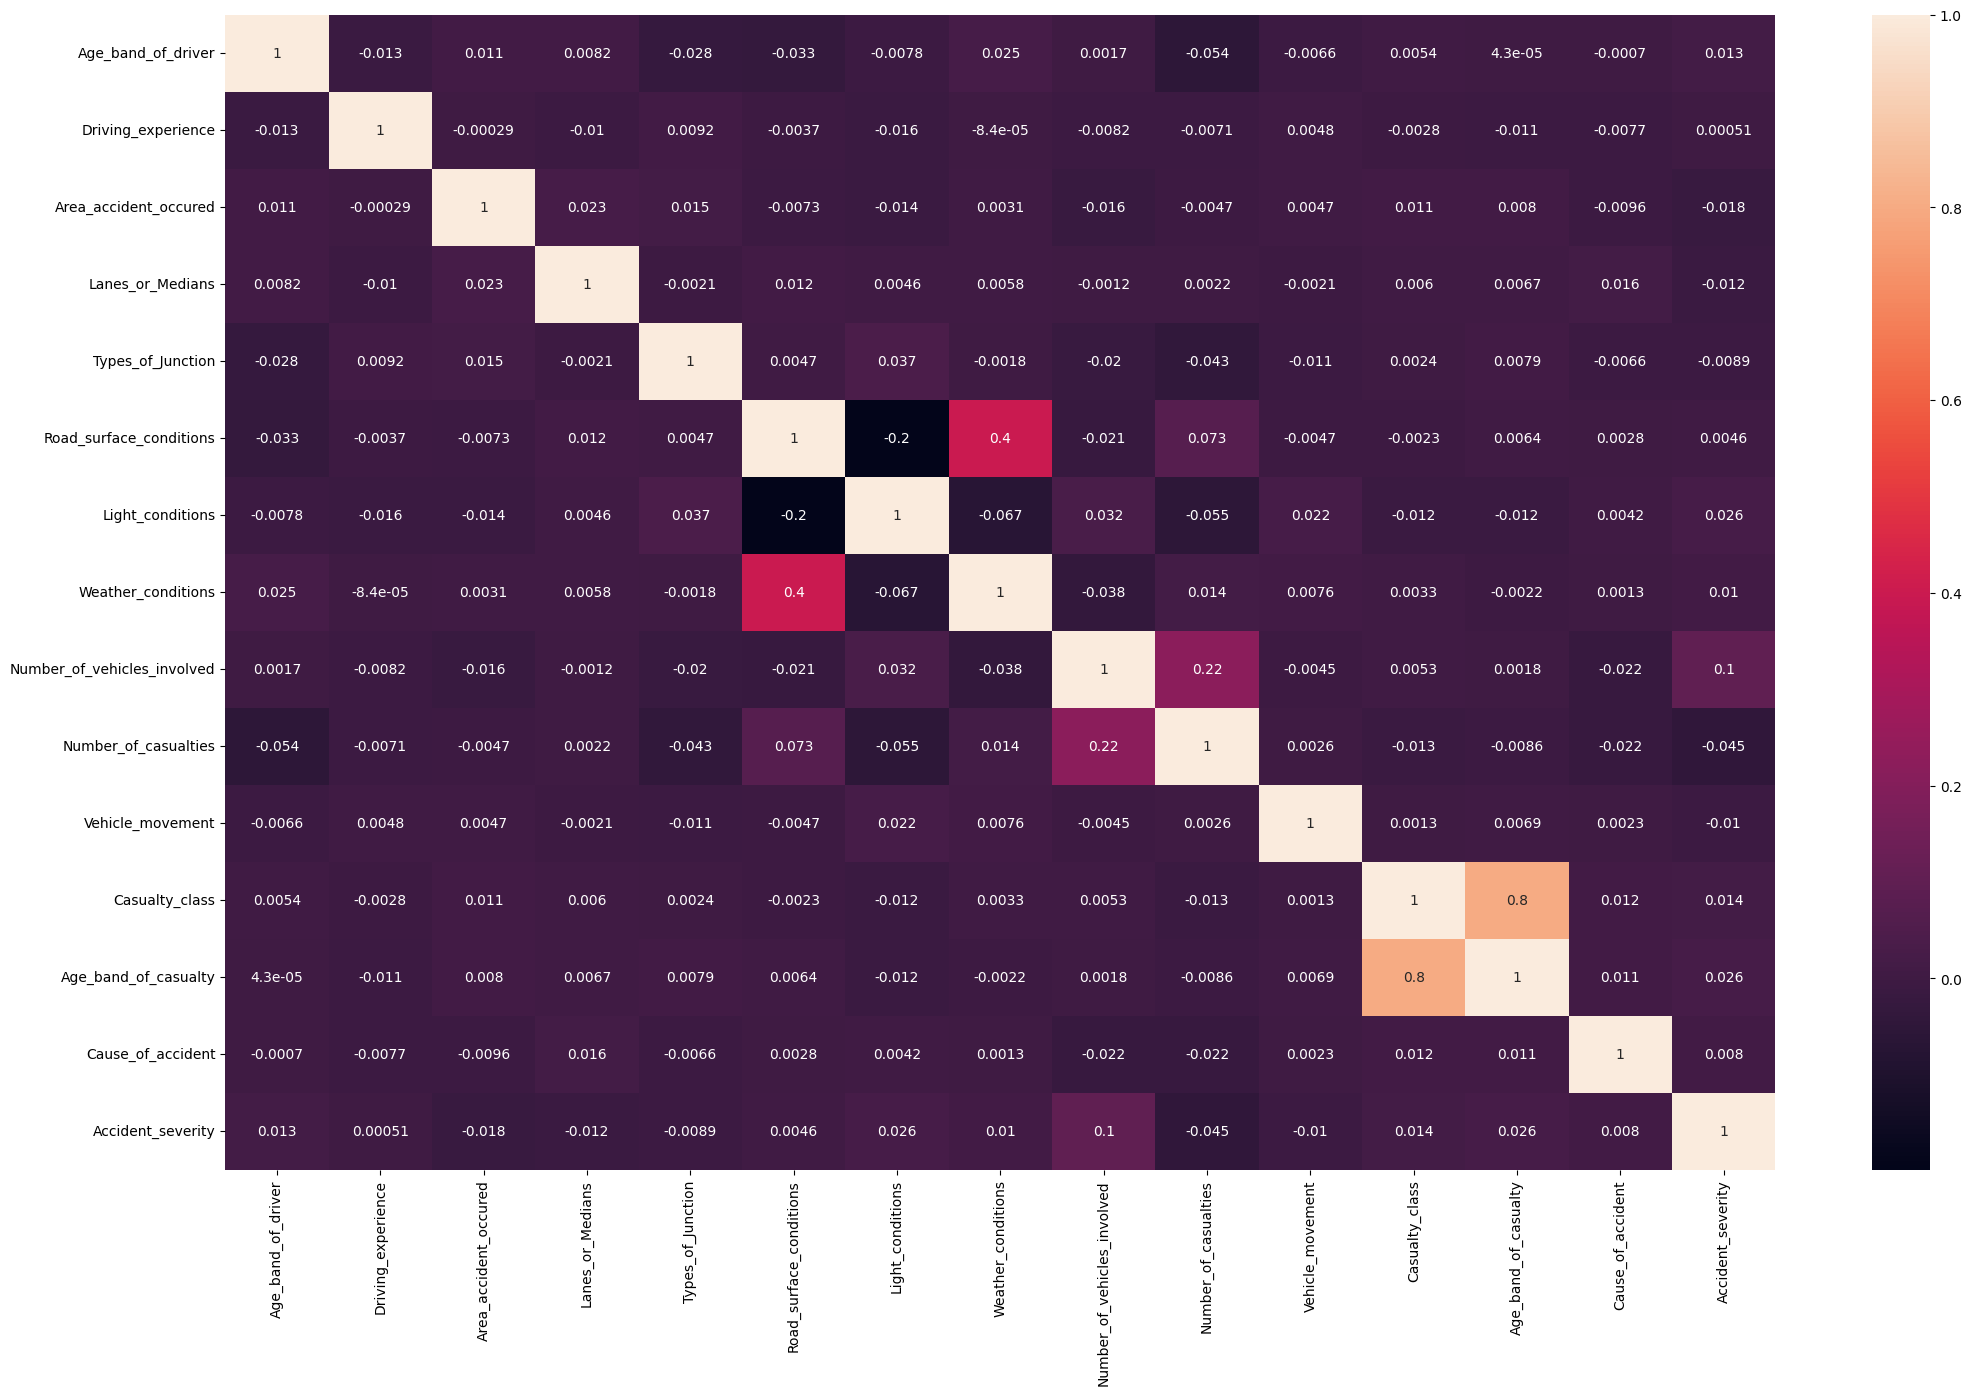

In [31]:
plt.figure(figsize=[25,15])
sns.heatmap(df.corr(),annot=True)

In [32]:
for col in df.select_dtypes(include='object'):
    if df[col].nunique() <= 22:
        sns.countplot(y=col, data=df)
        plt.show()

**Upsampling**
---



In [33]:
x = df.drop('Accident_severity', axis=1)
y = df['Accident_severity']

xtrain, xtest, ytrain, ytest = train_test_split(x, y, test_size=0.3, random_state=42)
print(xtrain.shape, xtest.shape, ytrain.shape, ytest.shape)

(8621, 14) (3695, 14) (8621,) (3695,)


In [34]:
xtrain.columns

Index(['Age_band_of_driver', 'Driving_experience', 'Area_accident_occured',
       'Lanes_or_Medians', 'Types_of_Junction', 'Road_surface_conditions',
       'Light_conditions', 'Weather_conditions', 'Number_of_vehicles_involved',
       'Number_of_casualties', 'Vehicle_movement', 'Casualty_class',
       'Age_band_of_casualty', 'Cause_of_accident'],
      dtype='object')

In [35]:
# upsampling using smote

counter = Counter(ytrain)

print("=============================")

for k,v in counter.items():
    per = 100*v/len(ytrain)
    print(f"Class= {k}, n={v} ({per:.2f}%)")

oversample = SMOTE()
xtrain, ytrain = oversample.fit_resample(xtrain, ytrain)
counter = Counter(ytrain)

print("=============================")

for k,v in counter.items():
    per = 100*v/len(ytrain)
    print(f"Class= {k}, n={v} ({per:.2f}%)")

print("=============================")

print("Upsampled data shape: ", xtrain.shape, ytrain.shape)

Class= 2, n=7324 (84.96%)
Class= 1, n=1191 (13.82%)
Class= 0, n=106 (1.23%)
Class= 2, n=7324 (33.33%)
Class= 1, n=7324 (33.33%)
Class= 0, n=7324 (33.33%)
Upsampled data shape:  (21972, 14) (21972,)


**Splitting test and train data**
---



In [36]:
x=df.drop(columns=["Accident_severity"])
y=df["Accident_severity"]

In [37]:
models={"LogisticRegression":LogisticRegression(),
        "DecisionTreeClassifier":DecisionTreeClassifier(),
        "SVM":SVC(),
        "KNeighborsClassifier":KNeighborsClassifier(),
        "GNB":GaussianNB(),
       "RandomForestClassifier":RandomForestClassifier(),
        "AdaBoostClassifier":AdaBoostClassifier(),
        }

In [38]:
def modelAccuracy(models,x,y,scaleFlag):
    #train/Test
    xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.2,random_state=0)
    acc_result={}
    for name,model in models.items():

        #1.Transformer -> 2.Model
        if(scaleFlag==1):
            model_pipeline=Pipeline([('MinMaxScler',MinMaxScaler()),('model',model)])
        elif(scaleFlag==2):
             model_pipeline=Pipeline([('StandardScaler',StandardScaler()),('model',model)])
        else:
            model_pipeline=Pipeline([('model',model)])

        #training/testing on model pipeline
        model_fit=model_pipeline.fit(xtrain,ytrain)
        ypred=model_fit.predict(xtest)
        acc=accuracy_score(ytest,ypred)
        print("The Accuracy for ",name," is :",acc)
        acc_result[name]=acc
    return acc_result

In [39]:
def bestModel(result):
    high=0
    for name,acc in result.items():
        if acc>high:
            high=acc
            model_name=name
    print("Best Model is ",model_name," with accuaracy =>",high)

In [40]:
acc=modelAccuracy(models,x,y,1)

The Accuracy for  LogisticRegression  is : 0.84375
The Accuracy for  DecisionTreeClassifier  is : 0.7491883116883117
The Accuracy for  SVM  is : 0.84375
The Accuracy for  KNeighborsClassifier  is : 0.8234577922077922
The Accuracy for  GNB  is : 0.8295454545454546
The Accuracy for  RandomForestClassifier  is : 0.8441558441558441
The Accuracy for  AdaBoostClassifier  is : 0.84375


In [41]:
bestModel(acc)

Best Model is  RandomForestClassifier  with accuaracy => 0.8441558441558441


In [42]:
from sklearn.metrics import classification_report

best_model = RandomForestClassifier()
best_model.fit(xtrain,ytrain)
ypred = best_model.predict(xtest)

print(classification_report(ytest, ypred))


              precision    recall  f1-score   support

           0       0.03      0.02      0.02        52
           1       0.24      0.23      0.23       552
           2       0.85      0.86      0.86      3091

    accuracy                           0.76      3695
   macro avg       0.37      0.37      0.37      3695
weighted avg       0.75      0.76      0.75      3695



In [43]:
!pip install streamlit pyngrok joblib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 53.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 74.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [streamlit]


In [44]:
!ngrok authtoken 2vcdMGMuej72P2uCfBZlRvcmAUa_3BbLnMajyrFv7fFG58xW9

Authtoken saved to configuration file: /root/.config/ngrok/ngrok.yml


In [45]:
%%writefile app.py
import streamlit as st
import joblib
import numpy as np
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/ML Lab/Road Accident Prediction Using ML/Road accident Dataset.csv')
from sklearn.preprocessing import LabelEncoder
LE = LabelEncoder()
df_encoded = df.apply(LE.fit_transform)

# dropping columns that can cause imbalance while imputation
lists=['Vehicle_driver_relation','Road_allignment','Type_of_vehicle','Pedestrian_movement','Type_of_collision', 'Work_of_casuality', 'Fitness_of_casuality','Day_of_week','Casualty_severity','Time','Sex_of_driver','Educational_level','Defect_of_vehicle','Owner_of_vehicle','Service_year_of_vehicle', 'Road_surface_type','Sex_of_casualty']
df.drop(columns = lists, inplace=True)

st.set_page_config(page_title="Road Accident Severity Prediction", layout="wide")
st.title("🚦 Road Accident Severity Predictor")
st.write("Predict the severity of a road accident using machine learning.")

# Load the trained model and scaler
@st.cache_resource
def load_model():
    try:
        model = joblib.load("road_accident_model.pkl")
        scaler = joblib.load("minmax_scaler.pkl")
        return model, scaler
    except Exception as e:
        st.error(f"Model loading error: {e}")
        return None, None

model, scaler = load_model()

if model is not None:
    st.success("Model & Scaler loaded successfully!")
    st.title("Feature Encoding Visualization")
    for col in df.columns:
      st.subheader(f"Column: {col}")
      mapping = dict(zip(LE.fit_transform(df[col].unique()), df[col].unique()))
      st.write(pd.DataFrame({'Encoded Value': mapping.keys(), 'Original Value': mapping.values()}))

    # Collect user input
    st.subheader("Enter Input Features")

    col1, col2 = st.columns(2)

with col1:
    num_casualties = st.number_input("Number of Casualties(encoded)", 0, 8, 4)
    num_vehicles = st.number_input("Number of Vehicles Involved", min_value=0, step=1)
    age_band = st.slider("Age Band of Driver (encoded)", 0, 5, 2)
    driving_experience = st.slider("Driving Experience (encoded)", 0, 8, 5)
    casualty_class = st.slider("Casualty Class (encoded)", 0, 5, 2)
    age_band_casualty = st.slider("Age Band of Casualty (encoded)", 0, 10, 5)
    cause_of_accident = st.slider("Cause of Accident (encoded)", 0, 10, 5)

with col2:
    area = st.slider("Area Accident Occurred (encoded)", 0, 15, 5)
    lanes_or_medians = st.slider("Lanes or Medians (encoded)", 0, 8, 5)
    junction_type = st.slider("Type of Junction (encoded)", 0, 9, 5)
    road_surface = st.slider("Road Surface Conditions (encoded)", 0, 4, 2)
    light_conditions = st.slider("Light Conditions (encoded)", 0, 4, 3)
    weather_conditions = st.slider("Weather Conditions (encoded)", 0, 9, 4)
    vehicle_movement = st.slider("Vehicle Movement (encoded)", 0, 5, 2)


    # Create input vector
    features = np.array([
        num_casualties,
        num_vehicles,
        age_band,
        driving_experience,
        area,
        lanes_or_medians,
        junction_type,
        vehicle_movement,
        casualty_class,
        age_band_casualty,
        cause_of_accident,
        road_surface,
        light_conditions,
        weather_conditions
    ]).reshape(1, -1)

    # Predict
    if st.button("Predict Severity"):
        try:
            scaled_input = scaler.transform(features)
            prediction = model.predict(scaled_input)[0]
            st.subheader("🚨 Prediction Result")
            severity_map = {
                0: "Slight Injury",
                1: "Serious Injury",
                2: "Fatal Injury"
            }
            severity_label = severity_map.get(prediction, "Unknown")

            if prediction == 0:
                st.success(f"Prediction: {severity_label}")
            elif prediction == 1:
                st.warning(f"Prediction: {severity_label}")
            else:
                st.error(f"Prediction: {severity_label}")

        except Exception as e:
            st.error(f"Prediction error: {e}")
    else:
      st.error("Model or scaler not loaded.")


Writing app.py


In [46]:
import joblib

from sklearn.ensemble import RandomForestClassifier # import the RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
best_model = RandomForestClassifier()
best_model.fit(xtrain, ytrain)
# Save the best model and scaler
joblib.dump(best_model, "road_accident_model.pkl")
joblib.dump(MinMaxScaler().fit(x), "minmax_scaler.pkl")


['minmax_scaler.pkl']

In [47]:
from pyngrok import ngrok
import os

# Kill previous tunnels
ngrok.kill()

# Start the Streamlit app
os.system("streamlit run app.py &")


public_url = ngrok.connect(addr='8501', proto="http")
print("🌍 Open the app here:", public_url)

🌍 Open the app here: NgrokTunnel: "https://d63a-34-106-113-89.ngrok-free.app" -> "http://localhost:8501"


In [48]:
%%writefile app.py
import streamlit as st
import joblib
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder

st.set_page_config(page_title="Road Accident Severity Prediction", layout="wide")
st.title("🚦 Road Accident Severity Predictor")

# Load the dataset safely to reconstruct mappings
try:
    df = pd.read_csv('/content/RTA Dataset.csv')
    # Drop unwanted columns exactly as we did in the notebook
    lists = ['Vehicle_driver_relation','Road_allignment','Type_of_vehicle','Pedestrian_movement','Type_of_collision', 'Work_of_casuality', 'Fitness_of_casuality','Day_of_week','Casualty_severity','Time','Sex_of_driver','Educational_level','Defect_of_vehicle','Owner_of_vehicle','Service_year_of_vehicle', 'Road_surface_type','Sex_of_casualty']
    df.drop(columns=[col for col in lists if col in df.columns], inplace=True, errors='ignore')

    # Fill missing values using mode values like in the notebook training
    for col in df.columns:
        df[col].fillna(df[col].mode()[0], inplace=True)
except Exception as e:
    st.error(f"Dataset loading error: {e}")
    df = None

# Load trained model and scaler
@st.cache_resource
def load_model_and_scaler():
    try:
        model = joblib.load("road_accident_model.pkl")
        scaler = joblib.load("minmax_scaler.pkl")
        return model, scaler
    except Exception as e:
        return None, None

model, scaler = load_model_and_scaler()

if model is None or scaler is None:
    st.error("❌ Failed to load the ML model or scaler. Ensure 'road_accident_model.pkl' and 'minmax_scaler.pkl' are present in /content/")
else:
    st.success("✅ ML Model & Scaler loaded successfully!")

    # Visualizer of mappings
    if df is not None:
        with st.expander("📊 View Feature Encoding Maps", expanded=False):
            LE = LabelEncoder()
            for col in df.columns:
                if col != 'Accident_severity':
                    st.write(f"**{col}** Mapping:")
                    original_vals = df[col].unique()
                    encoded_vals = LE.fit_transform(original_vals)
                    mapping_df = pd.DataFrame({
                        'Encoded Integer': encoded_vals,
                        'Original Label': original_vals
                    }).sort_values(by='Encoded Integer')
                    st.dataframe(mapping_df, hide_index=True)

    st.subheader("🔮 Predict Accident Severity")
    st.write("Please fill in the incident parameters below. Built-in input validations protect against logical edge cases.")

    col1, col2 = st.columns(2)

    with col1:
        # Edge Case Input Validations
        num_vehicles = st.number_input(
            "Number of Vehicles Involved",
            min_value=1,
            max_value=100,
            value=2,
            step=1,
            help="Must be at least 1 vehicle involved."
        )
        num_casualties = st.number_input(
            "Number of Casualties",
            min_value=1,
            max_value=100,
            value=1,
            step=1,
            help="Must be at least 1 casualty recorded."
        )

        age_band = st.slider("Age Band of Driver (encoded)", 0, 4, 2)
        driving_experience = st.slider("Driving Experience (encoded)", 0, 6, 2)
        area = st.slider("Area Accident Occurred (encoded)", 0, 13, 5)
        lanes_or_medians = st.slider("Lanes or Medians (encoded)", 0, 6, 2)
        junction_type = st.slider("Type of Junction (encoded)", 0, 7, 2)

    with col2:
        road_surface = st.slider("Road Surface Conditions (encoded)", 0, 4, 0)
        light_conditions = st.slider("Light Conditions (encoded)", 0, 3, 0)
        weather_conditions = st.slider("Weather Conditions (encoded)", 0, 8, 1)
        vehicle_movement = st.slider("Vehicle Movement (encoded)", 0, 12, 2)
        casualty_class = st.slider("Casualty Class (encoded)", 0, 3, 3)
        age_band_casualty = st.slider("Age Band of Casualty (encoded)", 0, 5, 5)
        cause_of_accident = st.slider("Cause of Accident (encoded)", 0, 19, 1)

    # Trigger Prediction
    if st.button("Predict Severity", type="primary"):
        # Validation check
        if num_vehicles < 1:
            st.error("⚠️ Edge Case Detected: An accident must involve at least 1 vehicle.")
        elif num_casualties < 1:
            st.error("⚠️ Edge Case Detected: The casualty count must be at least 1 for any reported accident parameters.")
        else:
            # Align features with the exact order trained on
            # ['Age_band_of_driver', 'Driving_experience', 'Area_accident_occured',
            #  'Lanes_or_Medians', 'Types_of_Junction', 'Road_surface_conditions',
            #  'Light_conditions', 'Weather_conditions', 'Number_of_vehicles_involved',
            #  'Number_of_casualties', 'Vehicle_movement', 'Casualty_class',
            #  'Age_band_of_casualty', 'Cause_of_accident']
            features = np.array([
                age_band,
                driving_experience,
                area,
                lanes_or_medians,
                junction_type,
                road_surface,
                light_conditions,
                weather_conditions,
                num_vehicles,
                num_casualties,
                vehicle_movement,
                casualty_class,
                age_band_casualty,
                cause_of_accident
            ]).reshape(1, -1)

            try:
                # Standardize/Scale and Predict
                scaled_features = scaler.transform(features)
                prediction = model.predict(scaled_features)[0]

                st.markdown("--- ")
                st.subheader("🚨 Prediction Result")

                severity_map = {
                    0: "Slight Injury",
                    1: "Serious Injury",
                    2: "Fatal Injury"
                }
                severity_label = severity_map.get(prediction, f"Class {prediction}")

                if prediction == 0:
                    st.success(f"🟢 Predicted Severity: **{severity_label}**")
                elif prediction == 1:
                    st.warning(f"🟡 Predicted Severity: **{severity_label}**")
                else:
                    st.error(f"🔴 Predicted Severity: **{severity_label}**")
            except Exception as e:
                st.error(f"An error occurred during prediction: {e}")


Overwriting app.py


In [50]:
# Restarting Streamlit background application processes cleanly
!pkill streamlit
!nohup streamlit run app.py &

nohup: appending output to 'nohup.out'
